# Data Mining Project

### TASK: Classification by KNN
* #### Classification of at least 1 target variable of your choice:

  - You should discuss the choice of the attributes and identify the best parameter
    configurations (e.g. gain criterion for trees, best k for KNN etc.).
  - Discussion
  - Evaluate the quantitative performance of the algorithms w.r.t. confusion matrix, accuracy, precision, recall, F1, ROC curve
  - Discuss some insight (e.g. try to interpret the tree(s))
  - Which is the best algorithm? Best can be studied w.r.t. the performance evaluation or other preferred point of view;

### Informazioni Generali
* **Corso:** Data Mining
* **Università:** Università di Pisa
* **Anno Accademico:** 2024/2025

### Autore
* **Studente:** Giuseppe Muschetta

### Dataset Utilizzato
* **Nome:** IMDb Dataset (Data Matrix)
* **Descrizione:** Dataset consisting of 21909 points in 23 dimensions

In [1]:
import pandas as pd
import os
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
# Global style setting for Seaborn and matplotlib plots
plt.style.use("dark_background")
sns.set_theme(
    style="darkgrid",
    context="notebook",
    palette="icefire",  # rocket, mako, crest, vlag, flare
    font="sans-serif",
    font_scale=1.1
)

# Other palette examples:
# dark mode: icefire, rocket, mako, crest, vlag, flare
# white theme: viridis, magma, plasma, inferno, cividis,

# Ottimizzazione dei caratteri (solo se vuoi)
plt.rcParams['axes.labelweight'] = 'bold'
plt.rcParams['axes.titleweight'] = 'bold'
plt.rcParams['axes.edgecolor'] = 'white'
plt.rcParams['axes.labelcolor'] = 'white'
plt.rcParams['xtick.color'] = 'lightgray'
plt.rcParams['ytick.color'] = 'lightgray'
plt.rcParams['text.color'] = 'white'
plt.rcParams['figure.facecolor'] = '#111111'
plt.rcParams['axes.facecolor'] = '#111111'
plt.rcParams['savefig.facecolor'] = '#111111'

In [3]:
# Create Directory for Plots ---
# To keep our project organized, we'll save all generated plots to a specific
# directory. This code creates a 'plots' directory if it doesn't already exist.

plots_dir = 'plots_classification/knn/'

if not os.path.exists(plots_dir):
    os.makedirs(plots_dir, exist_ok=True)
    print(f"Directory {plots_dir} created successfully.")
else:
    print(f"Directory {plots_dir} already exists.")

# Load the dataset ---
# Load the dataset from the provided CSV file into a pandas DataFrame, which is
# the primary data structure we will use for our analysis.

# Define the file path
dataset_dir = 'dataset/'
dataset_train = 'train_prepared.csv'
dataset_test = 'test_prepared.csv'

# Load the data
try:
    df_train = pd.read_csv(dataset_dir + dataset_train)
    print(f"dataset '{dataset_train}' loaded successfully.")
    print(f"The dataset contains {df_train.shape[0]} rows and {df_train.shape[1]} columns.")
    df_test = pd.read_csv(dataset_dir + dataset_test)
    print(f"dataset '{dataset_test}' loaded successfully.")
    print(f"The dataset contains {df_test.shape[0]} rows and {df_test.shape[1]} columns.")
except FileNotFoundError:
    print(f"Error: The dataset in the dir '{dataset_dir}' was not found. Please check the file path.")
    exit(1)


Directory plots_classification/knn/ already exists.
dataset 'train_prepared.csv' loaded successfully.
The dataset contains 15609 rows and 55 columns.
dataset 'test_prepared.csv' loaded successfully.
The dataset contains 5478 rows and 55 columns.


In [4]:
df_train.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Neogenic Nightmare Chapter 3: Hydro-Man,1995,\N,58,0,779,1,0,21,1,...,-0.33267,1.465542,-0.510552,-0.277418,0.236295,-0.367632,0.264517,-0.316269,-0.661879,-0.648047
1,Looping,1982,\N,58,0,11,1,0,1,0,...,-0.33267,-0.906068,-0.510552,-0.277418,0.236295,-2.524145,-0.517037,-0.316269,-0.661879,-0.648047
2,Idealnaya para,1992,\N,58,0,38,1,0,24,0,...,-0.33267,-0.236435,-0.510552,-0.277418,0.236295,-0.252666,-0.517037,-0.316269,-0.661879,-0.015936
3,MasterChef Celebrity México,2021,\N,58,0,15,22,0,56,0,...,-0.33267,-0.742626,1.535001,-0.277418,0.236295,0.488544,-0.517037,-0.316269,-0.661879,-0.648047
4,Lightdance,1995,\N,34,0,14,1,0,0,0,...,-0.33267,-0.779293,-0.510552,-0.277418,-0.452128,-3.147517,-0.517037,-0.316269,-0.661879,-0.015936


In [5]:
df_test.head()

,originalTitle,startYear,endYear,runtimeMinutes,awardWins,numVotes,totalImages,totalVideos,totalCredits,criticReviewsTotal,...,awardWins_proc,numVotes_proc,totalImages_proc,totalVideos_proc,runtimeMinutes_proc,totalCredits_proc,criticReviewsTotal_proc,awardNominationsExcludeWins_proc,numRegions_proc,userReviewsTotal_proc
0,Geologist of Animal Collective Performs Live a...,2015,\N,21,0,15,7,2,11,0,...,-0.33267,-0.742626,0.650519,2.972334,-1.064242,-0.912751,-0.517037,-0.316269,-0.661879,-0.648047
1,Shan gou 1999,1999,\N,58,0,304,10,0,40,9,...,-0.33267,0.932074,0.917236,-0.277418,0.236295,0.192232,2.079227,-0.316269,0.633799,1.355697
2,The Craftsman: Preserving the Last Higgins Boat,2023,\N,58,0,10,2,0,6,0,...,-0.33267,-0.955502,-0.170960,-0.277418,0.236295,-1.397490,-0.517037,-0.316269,-0.661879,-0.648047
3,Week 3: Tuesday,2020,\N,58,0,11,0,0,52,0,...,-0.33267,-0.906068,-1.091087,-0.277418,0.236295,0.423109,-0.517037,-0.316269,-0.661879,-0.648047
4,Traumhaus,1999,\N,90,0,145,2,0,44,1,...,-0.33267,0.513527,-0.170960,-0.277418,0.807562,0.275951,0.264517,-0.316269,-0.661879,-0.648047


In [6]:
df_train.info(verbose=True, memory_usage='deep', show_counts=True)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15609 entries, 0 to 15608
Data columns (total 55 columns):
 #   Column                            Non-Null Count  Dtype  
---  ------                            --------------  -----  
 0   originalTitle                     15609 non-null  object 
 1   startYear                         15609 non-null  int64  
 2   endYear                           15609 non-null  object 
 3   runtimeMinutes                    15609 non-null  int64  
 4   awardWins                         15609 non-null  int64  
 5   numVotes                          15609 non-null  int64  
 6   totalImages                       15609 non-null  int64  
 7   totalVideos                       15609 non-null  int64  
 8   totalCredits                      15609 non-null  int64  
 9   criticReviewsTotal                15609 non-null  int64  
 10  awardNominationsExcludeWins       15609 non-null  int64  
 11  numRegions                        15609 non-null  int64  
 12  user

--- Class Distribution for 'rating' (3 Tiers) ---

Counts:
rating_encoded
Good       6851
Poor       4419
Average    4339
Name: count, dtype: int64

Percentages:
rating_encoded
Good       43.89 %
Poor       28.31 %
Average     27.8 %
Name: proportion, dtype: object


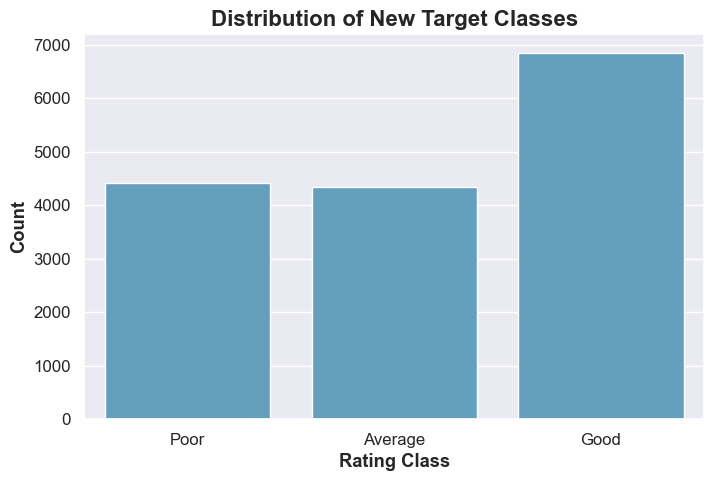

In [7]:
# --- Calculate Class Counts for the 3-Tier Rating System ---

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:  # Original ratings up to 6.0
        return 'Poor'
    elif encoded_rating <= 6: # Original ratings from 6.1 to 7.0
        return 'Average'
    else:  # Original ratings from 7.1 to 10.0
        return 'Good'

# Create a temporary column to see the distribution
# We will make this permanent in the next step
temp_binned_col = df_train['rating_encoded'].apply(assign_rating_class)

# Calculate and print the counts and percentages for each class
class_distribution = temp_binned_col.value_counts()
class_percentages = temp_binned_col.value_counts(normalize=True) * 100

print("--- Class Distribution for 'rating' (3 Tiers) ---")
print("\nCounts:")
print(class_distribution)
print("\nPercentages:")
print(class_percentages.round(2).astype(str) + ' %')

# Plotting the distribution for a clear visual
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(8, 5))
sns.barplot(x=class_distribution.index, y=class_distribution.values, order=['Poor', 'Average', 'Good'])
plt.title('Distribution of New Target Classes', fontsize=16, weight='bold')
plt.ylabel('Count')
plt.xlabel('Rating Class')
plt.show()

In [8]:
# --- 3.1. Target Variable and Feature Separation ---

# We will now make the creation of our target variable, 'rating_binned', permanent.
# The function defined previously will be applied to both the training and testing DataFrames.

def assign_rating_class(encoded_rating):
    """Groups the 10 encoded ratings into 3 final classes."""
    if encoded_rating <= 5:    # Corresponds to original ratings <= 6.0
        return 0 #'Poor'
    elif encoded_rating == 6:  # Corresponds to original ratings 6.1-7.0
        return 1 #'Average'
    else:                      # Corresponds to original ratings >= 7.1
        return 2 #'Good'

# Apply the function to create the target column
df_train['rating_binned'] = df_train['rating_encoded'].apply(assign_rating_class)
df_test['rating_binned'] = df_test['rating_encoded'].apply(assign_rating_class)

# Define the class names for later plotting
class_names = ['Poor', 'Average', 'Good']

print("Target variable 'rating_binned' created successfully.")
print("\nTrain set distribution:")
print(df_train['rating_binned'].value_counts())
print("\nTest set distribution:")
print(df_test['rating_binned'].value_counts())

Target variable 'rating_binned' created successfully.

Train set distribution:
rating_binned
2    6851
0    4419
1    4339
Name: count, dtype: int64

Test set distribution:
rating_binned
2    2414
0    1542
1    1522
Name: count, dtype: int64


In [9]:
# --- Separate Features (X) and Target (y) ---

# We define the feature matrix 'X' by dropping columns related to the target variable.
# The original 'averageRating' and the identifier 'tconst' were already removed
# during the preprocessing phase that created the '_prepared.csv' files.

# List of columns to drop to create the feature set
columns_to_drop = ['rating_encoded', 'rating_binned', 'originalTitle', 'endYear', 'startYear',
                   'runtimeMinutes', 'awardWins', 'numVotes', 'totalImages', 'totalVideos', 'totalCredits',
                   'criticReviewsTotal', 'awardNominationsExcludeWins', 'numRegions', 'userReviewsTotal']

# We add a check to ensure the columns exist before dropping, to prevent future errors
existing_columns_to_drop = [col for col in columns_to_drop if col in df_train.columns]

X_train = df_train.drop(columns=existing_columns_to_drop)
y_train = df_train['rating_binned']

X_test = df_test.drop(columns=existing_columns_to_drop)
y_test = df_test['rating_binned']

print("Features and target separated.")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

# Let's check the features
print("\nFeatures being used for training:")
print(X_train.columns.tolist())

Features and target separated.
X_train shape: (15609, 41)
y_train shape: (15609,)
X_test shape: (5478, 41)
y_test shape: (5478,)

Features being used for training:
['titleType_movie', 'titleType_short', 'titleType_tvEpisode', 'titleType_tvMiniSeries', 'titleType_tvMovie', 'titleType_tvSeries', 'titleType_tvShort', 'titleType_tvSpecial', 'titleType_video', 'titleType_videoGame', 'genres_Drama', 'genres_Comedy', 'genres_Short', 'genres_Action', 'genres_Documentary', 'genres_Crime', 'genres_Adventure', 'genres_Animation', 'genres_Romance', 'genres_Family', 'countryOfOrigin_US', 'countryOfOrigin_GB', 'countryOfOrigin_JP', 'countryOfOrigin_FR', 'countryOfOrigin_CA', 'countryOfOrigin_IN', 'countryOfOrigin_DE', 'countryOfOrigin_IT', 'countryOfOrigin_ES', 'countryOfOrigin_AU', 'startYear_proc', 'awardWins_proc', 'numVotes_proc', 'totalImages_proc', 'totalVideos_proc', 'runtimeMinutes_proc', 'totalCredits_proc', 'criticReviewsTotal_proc', 'awardNominationsExcludeWins_proc', 'numRegions_proc', '

#### Classification by KNN, BASELINE MODEL with k=5 default
* Our second model is K-Nearest Neighbors (KNN). Unlike Decision Trees, KNN is an instance-based or "lazy learning" algorithm.
* It does not learn an explicit  model from the training data.
* Instead, it memorizes the entire training dataset.
* To make a prediction for a new data point, KNN looks at the 'K' closest data points (the "neighbors") in the training set
* and assigns the class that is most common among those K neighbors.

 **Key Considerations for KNN:**
 - **Distance Metric:** The choice of how to measure "closeness" is crucial. Common metrics include Euclidean and Manhattan distance.
 - **Choice of K:** The number of neighbors (K) is the most critical hyperparameter. A small K can be sensitive to noise, while a large K can be
     computationally expensive and may oversmooth the decision boundaries.
 - **Feature Scaling:** KNN is highly sensitive to the scale of features. Since our `_proc` features are already standardized using `StandardScaler`, we are     perfectly set up for this model.

 **Steps:**
 1. Train a baseline KNN classifier with a standard value for K (e.g., K=5).
 2. Evaluate its initial performance.
 3. Use `GridSearchCV` to find the optimal hyperparameters (`n_neighbors`, `weights`, `metric`).
 4. Train the final, tuned model.
 5. Perform a thorough evaluation using a classification report, confusion matrix, and ROC curves.

--- Training Baseline KNN (K=5) ---
Making predictions on the test set...
Predictions complete.

Baseline Model Performance:
Accuracy: 0.5504

Classification Report:
              precision    recall  f1-score   support

        Poor       0.50      0.63      0.55      1542
     Average       0.39      0.33      0.36      1522
        Good       0.69      0.64      0.67      2414

    accuracy                           0.55      5478
   macro avg       0.53      0.53      0.53      5478
weighted avg       0.55      0.55      0.55      5478



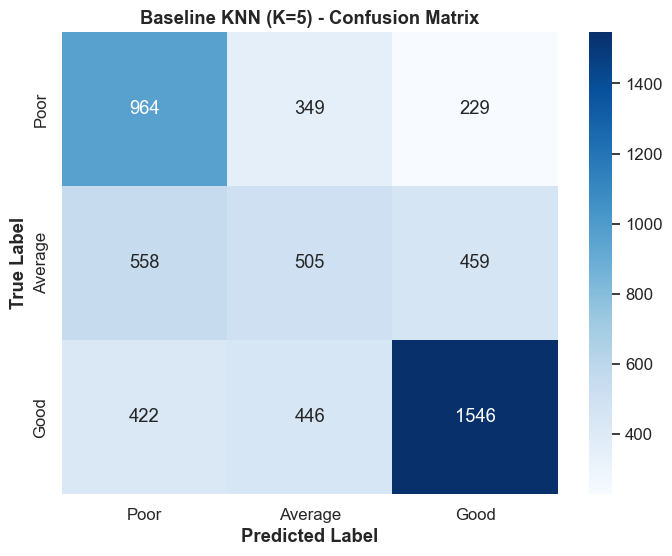

In [11]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# --- Baseline KNN ---
print("--- Training Baseline KNN (K=5) ---")

# 1. Instantiate the model. We'll start with K=5, a common default.
#    n_jobs=-1 will use all available CPU cores to speed up computation.
baseline_knn = KNeighborsClassifier(n_neighbors=5, n_jobs=-1)

# 2. Train the model (in KNN, this is just storing the data)
baseline_knn.fit(X_train, y_train)

# 3. Make predictions
# This step can be slow as it calculates distances for every test point.
print("Making predictions on the test set...")
y_pred_baseline = baseline_knn.predict(X_test)
print("Predictions complete.")

# 4. Evaluate the baseline model
print("\nBaseline Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_baseline):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_baseline, target_names=class_names))

# Plotting the Confusion Matrix for the baseline model
plt.figure(figsize=(8, 6))
cm_baseline = confusion_matrix(y_test, y_pred_baseline)
sns.heatmap(cm_baseline, annot=True, fmt='d', cmap='Blues', xticklabels=class_names, yticklabels=class_names)
plt.title('Baseline KNN (K=5) - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}knn_baseline_confusion_matrix.png', dpi=300)
plt.show()

#### TUNED MODEL: Searching for the optimal k

--- Inizio ricerca del K ottimale con il metodo a gomito ---
Testando K = 1...
Testando K = 2...
Testando K = 3...
Testando K = 4...
Testando K = 5...
Testando K = 6...
Testando K = 7...
Testando K = 8...
Testando K = 9...
Testando K = 10...
Testando K = 11...
Testando K = 12...
Testando K = 13...
Testando K = 14...
Testando K = 15...
Testando K = 16...
Testando K = 17...
Testando K = 18...
Testando K = 19...
Testando K = 20...
Testando K = 21...
Testando K = 22...
Testando K = 23...
Testando K = 24...
Testando K = 25...
Testando K = 26...
Testando K = 27...
Testando K = 28...
Testando K = 29...
Testando K = 30...
Testando K = 31...
Testando K = 32...
Testando K = 33...
Testando K = 34...
Testando K = 35...
Testando K = 36...
Testando K = 37...
Testando K = 38...
Testando K = 39...
Testando K = 40...
Testando K = 41...
Testando K = 42...
Testando K = 43...
Testando K = 44...
Testando K = 45...
Testando K = 46...
Testando K = 47...
Testando K = 48...
Testando K = 49...
Testando K = 50..

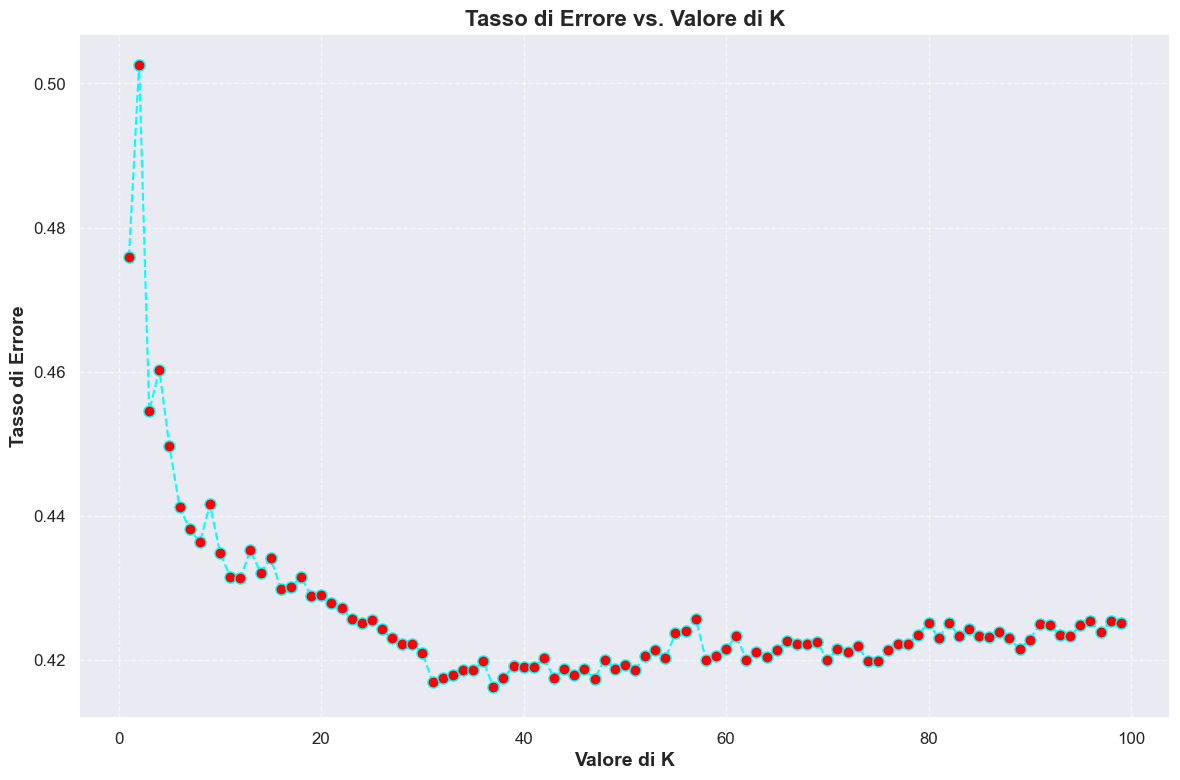

In [15]:
# --- Fase 1: Ricerca Visiva del K Ottimale (Metodo a Gomito) ---
print("--- Inizio ricerca del K ottimale con il metodo a gomito ---")

from sklearn.neighbors import KNeighborsClassifier
import numpy as np

# Creiamo una lista per salvare i tassi di errore
error_rate = []
# Definiamo un range di valori di K da testare (es. tutti i dispari da 1 a 50)
k_range = range(1, 100, 1)

# Cicliamo su ogni valore di K
for i in k_range:
    print(f"Testando K = {i}...")
    # Creiamo e addestriamo il modello
    knn = KNeighborsClassifier(n_neighbors=i, n_jobs=-1)
    knn.fit(X_train, y_train)
    # Facciamo la predizione
    pred_i = knn.predict(X_test)
    # Calcoliamo l'errore (1 - accuracy) e lo aggiungiamo alla lista
    error_rate.append(np.mean(pred_i != np.array(y_test)))

print("--- Ricerca completata ---")

# --- Creazione del Grafico a Gomito ---
plt.figure(figsize=(12, 8))
plt.plot(k_range, error_rate, color='cyan', linestyle='--', marker='o',
         markerfacecolor='red', markersize=8)
plt.title('Tasso di Errore vs. Valore di K', fontsize=16, weight='bold')
plt.xlabel('Valore di K', fontsize=14, weight='bold')
plt.ylabel('Tasso di Errore', fontsize=14, weight='bold')
plt.grid(True, linestyle='--', alpha=0.6)
plt.tight_layout()
plt.savefig(f'{plots_dir}knn_error_rate_vs_k.png', dpi=300)
plt.show()


--- Inizio GridSearchCV Mirata ---
Fitting 3 folds for each of 144 candidates, totalling 432 fits
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   0.2s
[CV] END ..metric=euclidean, n_neighbors=5, weights=distance; total time=   0.2s
[CV] END ..metric=euclidean, n_neighbors=5, weights=distance; total time=   0.2s
[CV] END ..metric=euclidean, n_neighbors=6, weights=distance; total time=   0.2s
[CV] END ..metric=euclidean, n_neighbors=6, weights=distance; total time=   0.2s
[CV] END ...metric=euclidean, n_neighbors=5, weights=uniform; total time=   0.3s
[CV] END ..metric=euclidean, n_neighbors=5, weights=distance; total time=   0.3s
[CV] END ...metric=euclidean, n_neighbors=6, weights=uniform; total time=   0.3s
[CV] END ...metric=euclidean, n_neighbors=6, weights=uniform; total time=   0.3s
[CV] END ...metric=euclidean, n_neighbors=6, weights=uniform; total time=   0.3s
[CV] END ..metric=euclidean, n_neighbors=6, weights=distance; total time=   0.2s
[CV] END .

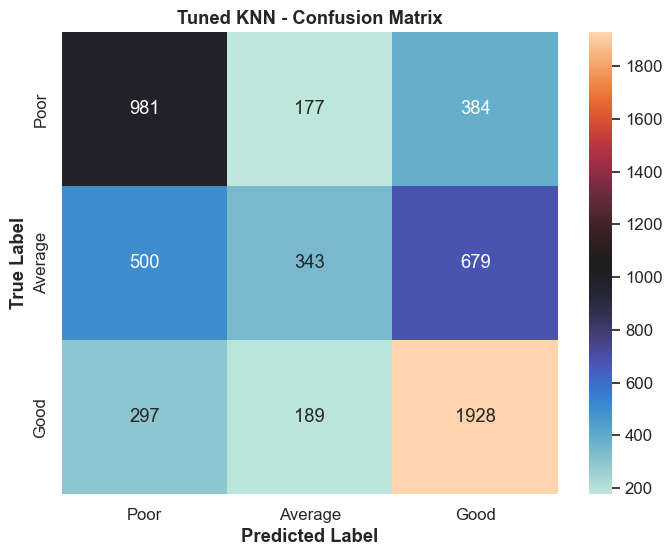

In [12]:
from sklearn.model_selection import GridSearchCV

# --- Fase 2: GridSearchCV Mirata perchè abbiamo già i valori di k più promettenti ---

# Definiamo una griglia di parametri più mirata
param_grid = {
    'n_neighbors': [5, 6, 7, 8, 9, 11, 13, 15, 19, 23, 27, 29, 31, 33, 35, 37, 39, 41, 43, 45, 47, 49, 51, 53],
    'weights': ['uniform', 'distance'],
    'metric': ['euclidean', 'manhattan', 'minkowski']
}

# Istanziamo il classificatore
knn_grid = KNeighborsClassifier(n_jobs=-1)

# Istanziamo GridSearchCV
# cv=3 per essere un po' più veloci, dato che abbiamo già una buona idea
grid_search = GridSearchCV(estimator=knn_grid, param_grid=param_grid,
                           cv=3, n_jobs=-1, verbose=2, scoring='accuracy')

# Avviamo la ricerca
print("\n--- Inizio GridSearchCV Mirata ---")
grid_search.fit(X_train, y_train)
print("--- GridSearchCV Mirata completata ---")

# Stampiamo i migliori parametri trovati
print("\nMigliori parametri trovati dalla ricerca mirata:")
print(grid_search.best_params_)

# Salviamo il modello migliore
best_knn = grid_search.best_estimator_

# --- Final Model Evaluation (Tuned KNN) ---
print("\n--- Evaluating Tuned KNN Model ---")

# Make predictions with the best model found by GridSearchCV
print("Making predictions with the best KNN model...")
y_pred_tuned = best_knn.predict(X_test)
print("Predictions complete.")

# Evaluate the tuned model
print("\nTuned Model Performance:")
print(f"Accuracy: {accuracy_score(y_test, y_pred_tuned):.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_tuned, target_names=class_names))

# Plotting the Confusion Matrix for the tuned model
plt.figure(figsize=(8, 6))
cm_tuned = confusion_matrix(y_test, y_pred_tuned)
sns.heatmap(cm_tuned, annot=True, fmt='d', cmap='icefire', xticklabels=class_names, yticklabels=class_names)
plt.title('Tuned KNN - Confusion Matrix', weight='bold')
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.savefig(f'{plots_dir}knn_tuned_confusion_matrix.png', dpi=300)
plt.show()

In [ ]:
#### ROC CURVE and AUC for tuned KNN

In [ ]:
# --- ROC Curve and AUC for Tuned KNN ---
print("\n--- Generating ROC Curves for Tuned KNN ---")

from sklearn.metrics import roc_curve, auc
from sklearn.preprocessing import label_binarize
from itertools import cycle

# Binarize the output labels for ROC curve calculation
# Note: y_test_bin is already available from the Decision Tree section, but we recalculate for clarity
y_test_bin = label_binarize(y_test, classes=[0, 1, 2])
n_classes = y_test_bin.shape[1]

# Get prediction probabilities for the test set
# This can be slow for KNN
print("Calculating prediction probabilities...")
y_score = best_knn.predict_proba(X_test)
print("Probabilities calculated.")

# Compute ROC curve and ROC area for each class
fpr = dict()
tpr = dict()
roc_auc = dict()
for i in range(n_classes):
    fpr[i], tpr[i], _ = roc_curve(y_test_bin[:, i], y_score[:, i])
    roc_auc[i] = auc(fpr[i], tpr[i])

# Compute micro-average ROC curve and ROC area
fpr["micro"], tpr["micro"], _ = roc_curve(y_test_bin.ravel(), y_score.ravel())
roc_auc["micro"] = auc(fpr["micro"], tpr["micro"])

# --- Plotting with Enhanced Aesthetics ---
plt.figure(figsize=(11, 9))

# Plot micro-average ROC
plt.plot(fpr["micro"], tpr["micro"],
         label=f'Micro-average ROC curve (area = {roc_auc["micro"]:0.3f})',
         color='magenta', linestyle=':', linewidth=4)

# Plot ROC for each class
colors = cycle(['#00FFFF', '#FF8C00', '#6495ED']) # Aqua, DarkOrange, CornflowerBlue
for i, color in zip(range(n_classes), colors):
    plt.plot(fpr[i], tpr[i], color=color, lw=2.5,
             label=f'ROC curve of class {class_names[i]} (area = {roc_auc[i]:0.3f})')

# Plot the random classifier line
plt.plot([0, 1], [0, 1], color='gray', lw=1.5, linestyle='--')

# Customize the plot
plt.xlim([-0.02, 1.0])
plt.ylim([0.0, 1.02])
plt.grid(color='gray', linestyle='--', linewidth=0.5, alpha=0.3)

# Labels, Title, and Legend
plt.xlabel('False Positive Rate', fontsize=14, weight='bold')
plt.ylabel('True Positive Rate', fontsize=14, weight='bold')
plt.title('KNN ROC Curves (One-vs-Rest)', fontsize=16, weight='bold')
plt.legend(loc="lower right", prop={'size': 12})
plt.tight_layout()
plt.savefig(f'{plots_dir}knn_roc_curves_final.png', dpi=300)
plt.show()